# Generating specified camera poses

In [1]:
import numpy as np
import json
import cv2

from copy import deepcopy
from scipy.spatial.transform import Rotation
from pathlib import Path

In [2]:
# Paths and initial data
transfomrs_path = Path("/home/repos/Neo/data/real/remove/single/tomato_soup_can/tomato_soup_can/before")

obj_coordinates = np.array([0.4, 0.2, 0.0])

In [3]:
# Load transformation
with open(transfomrs_path / 'transforms.json', 'r') as file:
    transforms_before = json.load(file)

In [16]:
def generate_hemisphere_vectors(radius, num_layers, origin):
    transformation_matrices = []
    
    thetas = np.linspace(0.0, np.pi / 2, num_layers + 2)
    for theta in thetas[1:-1]:

        print(theta)

        for j in range(4):
            
            phi = (np.pi / 2) * j

            x = (np.cos(theta) * np.sin(-phi) * radius) + origin[0]
            y = (np.cos(theta) * np.cos(-phi) * radius) + origin[1]
            z = (np.sin(theta) * radius) + origin[2]

            rot_1 = Rotation.from_euler('XYZ', [-np.pi / 2, -phi, 0.0], degrees=False)
            rot_2 = Rotation.from_euler('XYZ', [theta, 0.0, 0.0], degrees=False)
            R = (rot_1 * rot_2).as_matrix()

            trans_mat = np.eye(4)
            trans_mat[:3, 3:] = np.array([[x, y, z]]).T
            trans_mat[:3, :3] = R

            transformation_matrices.append(trans_mat)
    
    return transformation_matrices

# Parameters
radius = 0.5  # Radius of the hemisphere
num_layers = 3  # Number of points to generate

# Generate transformation matrices
specific_transformaitons = generate_hemisphere_vectors(radius, num_layers, obj_coordinates)

0.39269908169872414
0.7853981633974483
1.1780972450961724


# Visualization

In [5]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

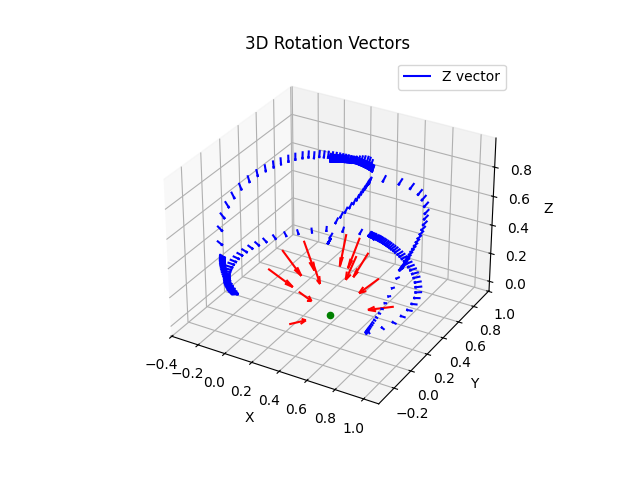

In [17]:
# Set up the figure
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Origin for arrows
origin = np.array([0, 0, 0])

# Loop through each matrix
for entry in transforms_before["frames"]:
    matrix = np.array(entry['transform_matrix'])
    
    # Extract the rotation vectors
    z_vector = matrix[:3, 2]  # Third column
    translation = matrix[:3, 3]  # Translation vector

    # Plot the vectors
    ax.quiver(*translation, *-z_vector, color='b', length=0.05, label='Z vector' if entry['colmap_im_id'] == 283 else "")

ax.scatter(*obj_coordinates, color='green')

for matrix in specific_transformaitons:
    # Extract the rotation vectors
    z_vector = matrix[:3, 2]  # Third column
    translation = matrix[:3, 3]  # Translation vector

    # Plot the vectors
    ax.quiver(*translation, *-z_vector, color='r', length=0.2, label='Z vector' if entry['colmap_im_id'] == 283 else "")

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('3D Rotation Vectors')
ax.legend()

# Show the plot
plt.show()